# Практическое занятие №2: Амплитудная и фазовая модуляция

## Часть 1. Генерация и визуализация модулированных сигналов

### Импорт библиотек и параметры

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from scipy.signal import hilbert
import ipywidgets as widgets
from IPython.display import Audio, display

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
rng = np.random.default_rng(2)
fs = 10000
T = 0.1
t = np.arange(int(fs*T)) / fs
fc, Ac = 1000, 1.0

### Модулирующий сигнал

В качестве модулирующего сигнала используйте сумму двух синусоид с частотами 100 Гц и 150 Гц, нормализованную к диапазону [-1, 1]. Постройте его график.

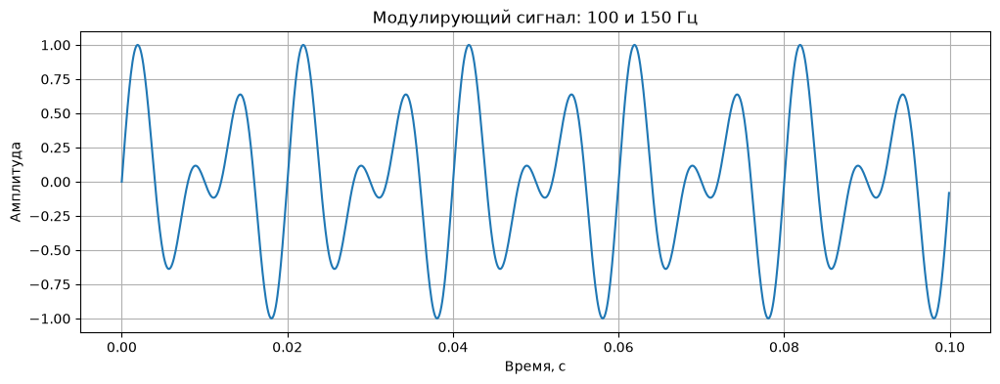

In [2]:
fm1, fm2 = 100, 150
m_t = np.sin(2*np.pi*fm1*t) + np.sin(2*np.pi*fm2*t)
m_t /= np.max(np.abs(m_t))
plt.plot(t, m_t)
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Модулирующий сигнал: 100 и 150 Гц')
plt.show()

### Амплитудная модуляция (АМ)

Формула АМ:
$$s_{AM}(t) = A_c [1 + a_{AM}\cdot m(t)] \cos(2\pi f_c t)
$$
Параметр $a_{AM}$ регулирует _глубину модуляции_, он не может быть больше 1 (при $a_{AM}>1$ и исходном сигнале $m(t)$, нормализованном на единицу, амплитуда результирующего сигнала в некоторые промежутки времени становится отрицательной).

In [3]:
a_am = 0.2
s_am = Ac * (1 + a_am*m_t) * np.cos(2*np.pi*fc*t)

### Фазовая модуляция (ФМ)

Формула ФМ:
$$
s_{PM}(t) = A_c \cos(2\pi f_c t + \beta \cdot m(t)),
$$

где $\beta$ – индекс фазовой модуляции.

In [4]:
beta_pm = 5
s_pm = Ac * np.cos(2*np.pi*fc*t + beta_pm*m_t)

### Задание 1.1.

Постройте на одном графике модулирующий сигнал и оба модулированных сигнала (АМ, ФМ). Оси и графики должны быть подписаны.

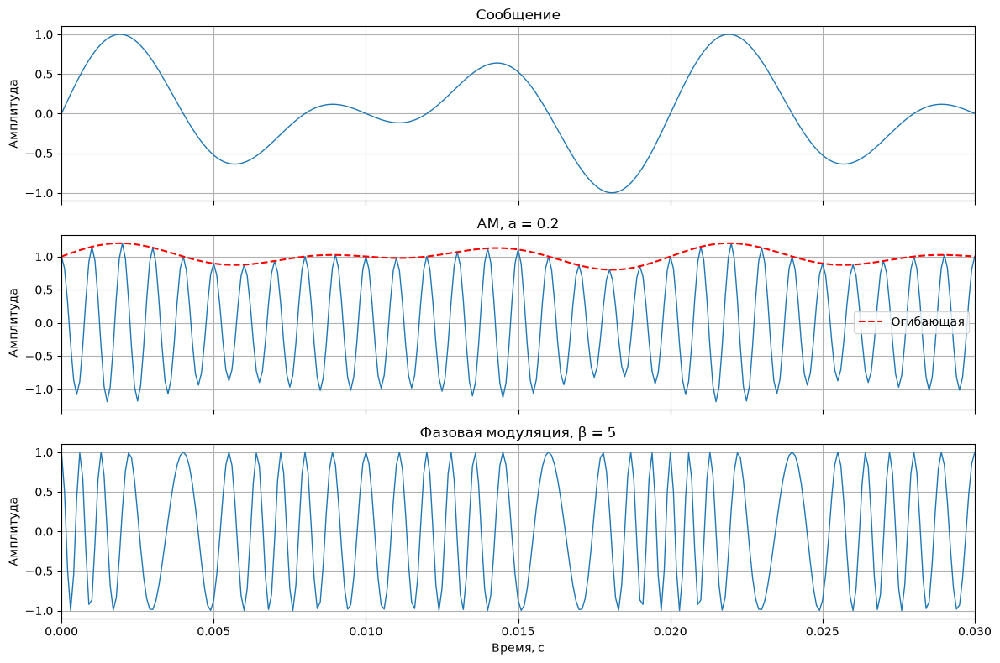

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, x, label in zip(axes, [m_t, s_am, s_pm], ['Сообщение', 'АМ, a = 0.2', 'Фазовая модуляция, β = 5']):
    ax.plot(t, x, lw=1)
    ax.set(ylabel='Амплитуда', title=label, xlim=(0, 0.03))
axes[1].plot(t, Ac*(1+a_am*m_t), 'r--', label='Огибающая')
axes[1].legend()
axes[-1].set_xlabel('Время, с')
plt.tight_layout()
plt.show()

## Часть 2. Спектральный анализ модулированных сигналов

### Задание 2.1. Функция построения амплитудного спектра
Реализуйте функцию построения амплитудного спектра ```plot_spectrum(s,fs,title)```
Значения аргументов:
* `s` - массив, содержащий значения сигнала
* `fs` - частота отсчётов сигнала
* `title` - заголовок графика, выводимый сверху

На графике по горизонтальной оси должна быть отложена частота в герцах, а по вертикальной - амплитуда гармоники. График должен строиться только для положительных значений частоты. Оси должны быть подписаны.

In [6]:
def amplitude_spectrum(s, fs):
    freq = np.fft.rfftfreq(len(s), 1/fs)
    amp = np.abs(np.fft.rfft(s)) / len(s)
    amp[1:(len(s)+1)//2] *= 2
    return freq, amp

def plot_spectrum(s, fs, title):
    freq, amp = amplitude_spectrum(s, fs)
    plt.plot(freq, amp)
    plt.xlabel('Частота, Гц')
    plt.ylabel('Амплитуда')
    plt.title(title)
    plt.show()

### Спектр АМ
Постройте спектр амплитудно-модулированного сигнала

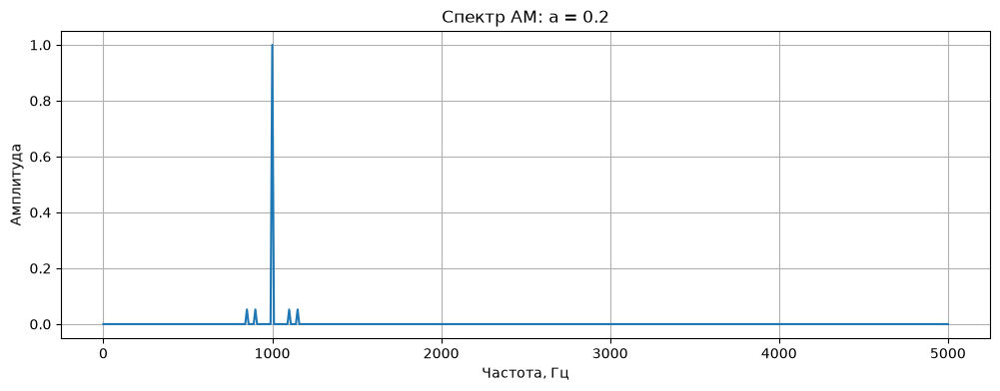

850 Гц: 0.052474
900 Гц: 0.052474
1000 Гц: 1.000000
1100 Гц: 0.052474
1150 Гц: 0.052474


In [7]:
plot_spectrum(s_am, fs, f'Спектр АМ: a = {a_am}')
freq, amp = amplitude_spectrum(s_am, fs)
for f in [850, 900, 1000, 1100, 1150]:
    i = np.argmin(abs(freq-f))
    print(f'{f} Гц: {amp[i]:.6f}')

### Задание 2.2. Спектр ФМ при разных индексах модуляции
Постройте спектр фазово-модулированного сигнала

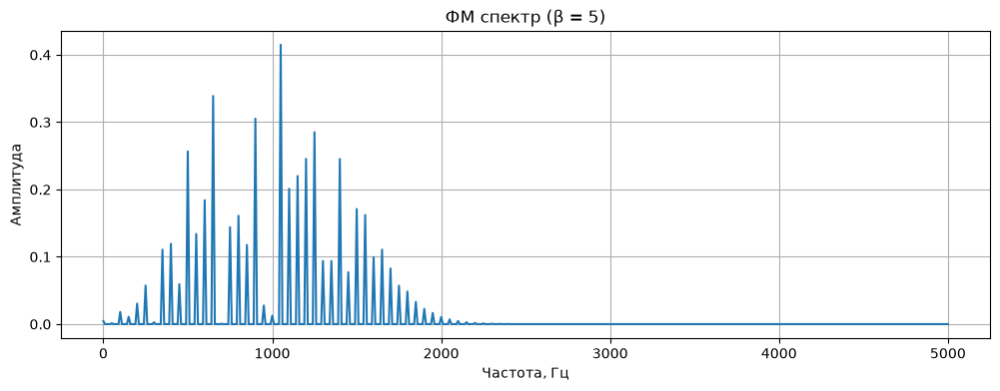

In [8]:
plot_spectrum(s_pm, fs, f'ФМ спектр (β = {beta_pm})')

Постройте на одном графике спектры для разных индексов модуляции (например, β = 0.1, 0.3, 1, 2, 5, 10). Оси и графики должны быть подписаны.

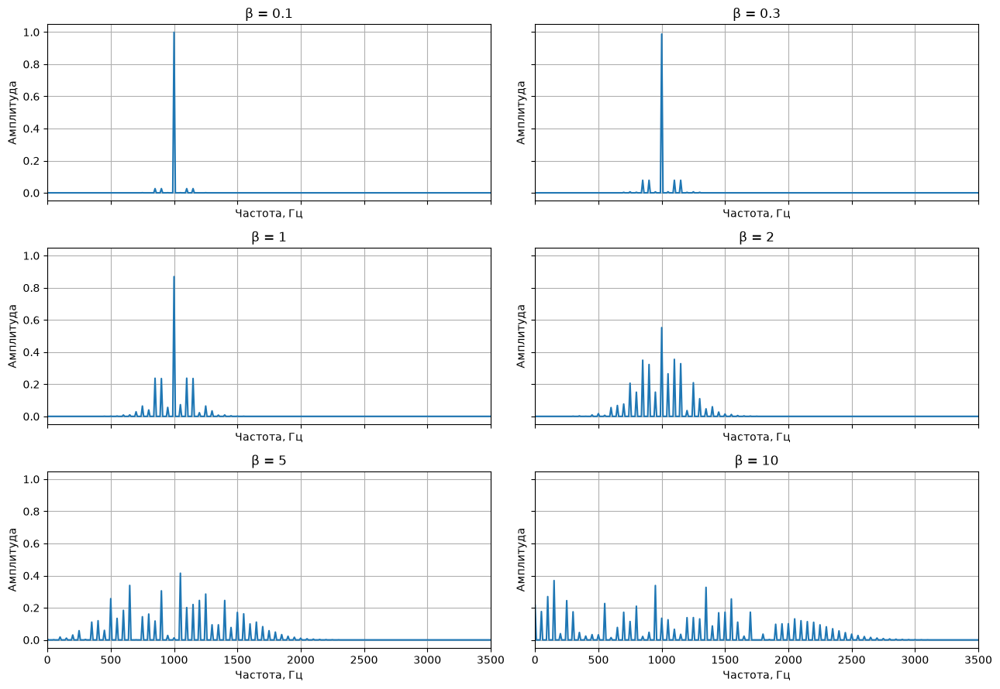

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True, sharey=True)
for ax, beta in zip(axes.flat, [0.1, 0.3, 1, 2, 5, 10]):
    x_pm = np.cos(2*np.pi*fc*t + beta*m_t)
    f, amp = amplitude_spectrum(x_pm, fs)
    ax.plot(f, amp)
    ax.set(title=f'β = {beta}', xlim=(0, 3500), xlabel='Частота, Гц', ylabel='Амплитуда')
plt.tight_layout()
plt.show()

### Задание 2.3. Интерактивное исследование спектра ФМ
Создайте интерактивный график для исследования зависимости спектра ФМ-сигнала от индекса модуляции.

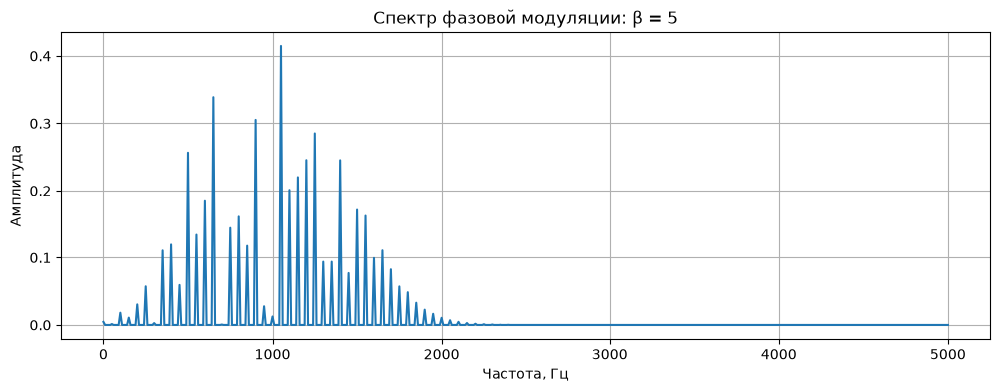

interactive(children=(FloatSlider(value=5.0, description='beta', max=20.0, min=0.1), Output()), _dom_classes=(…

<function __main__.pm_spectrum(beta=5)>

In [10]:
def pm_spectrum(beta=5):
    s = Ac*np.cos(2*np.pi*fc*t + beta*m_t)
    plot_spectrum(s, fs, f'Спектр фазовой модуляции: β = {beta:g}')

pm_spectrum(5)
widgets.interact(pm_spectrum, beta=(0.1, 20, 0.1))

**Вопросы:**
- Почему спектр АМ содержит только пять ярко выраженных компоненты (несущая и по две боковых с каждой стороны от неё)?
- Опишите, как выглядит спектр ФМ при малых β?
- Что происходит с амплитудой несущей и боковыми полосами ФМ при увеличении β?

У АМ я вижу несущую 1000 Гц и четыре боковых пика: 850, 900, 1100 и 1150 Гц. Две частоты сообщения дают по паре пиков. При маленьком β у ФМ тоже большая несущая и слабые боковые составляющие. Дальше β растёт, спектр становится шире, а несущая то уменьшается, то снова растёт.

## Часть 3. Демодуляция сигналов

### Задание 3.1. Демодуляция АМ с помощью преобразования Гильберта

Преобразование Гильберта позволяет получить аналитический сигнал, огибающая которого содержит исходное сообщение.

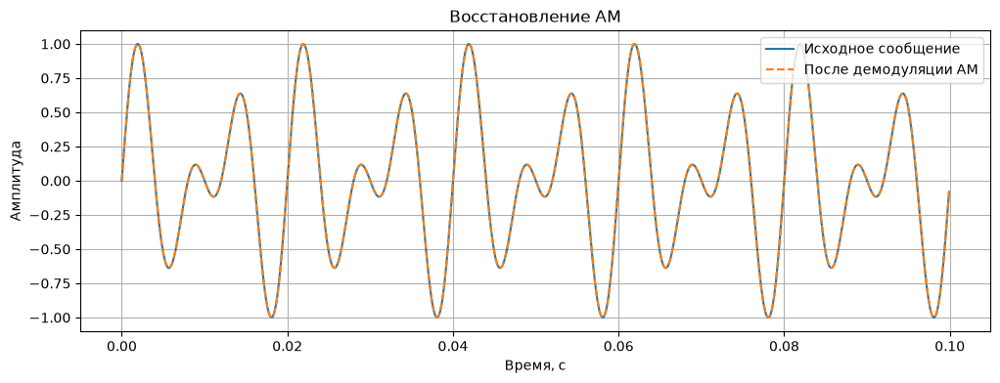

In [11]:
analytic_am = hilbert(s_am)
envelope = np.abs(analytic_am)
demod_am = (envelope/Ac - 1) / a_am
plt.plot(t, m_t, label='Исходное сообщение')
plt.plot(t, demod_am, '--', label='После демодуляции АМ')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Восстановление АМ')
plt.legend()
plt.show()

Вычислите среднеквадратичную ошибку между исходным и восстановленным сообщением с помощью функции `np.std`.

In [12]:
print('Ошибка АМ:', np.std(demod_am - m_t))

Ошибка АМ: 8.789186229402094e-14


### Демодуляция ФМ сигнала

Для ФМ информация заключена в отклонении фазы от линейного тренда. Используем аналитический сигнал и выделим мгновенную фазу.

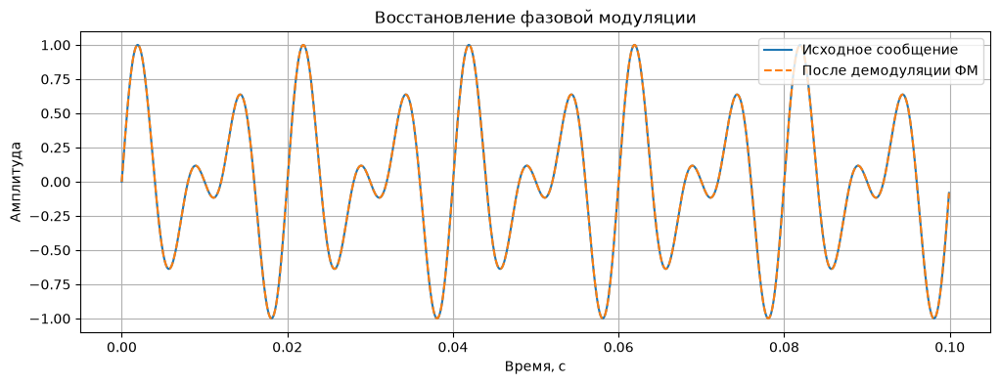

RMSE ФМ при β = 5: 0.000984


In [13]:
analytic_pm = hilbert(s_pm)
inst_phase = np.unwrap(np.angle(analytic_pm))
phase_no_carrier = inst_phase - 2*np.pi*fc*t
demod_pm = (phase_no_carrier - phase_no_carrier.mean()) / beta_pm
plt.plot(t, m_t, label='Исходное сообщение')
plt.plot(t, demod_pm, '--', label='После демодуляции ФМ')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Восстановление фазовой модуляции')
plt.legend()
plt.show()
print(f'RMSE ФМ при β = {beta_pm}: {np.sqrt(np.mean((demod_pm-m_t)**2)):.6f}')

**Вопрос:** Почему важно использовать `np.unwrap` для фазы?

Без `unwrap` фаза скачет с π на −π, и эти скачки попадают в восстановленный сигнал.  получаем непрерывную фазу и вычесть несущую.

## Часть 4. Устойчивость к шумам

Беру музыку из `data/sample-3s.wav`. Папка `data` должна лежать рядом с папкой `seminars`.

In [14]:
data_dir = Path('data') if Path('data').is_dir() else Path('../data')

In [15]:
fs_audio, melody = wavfile.read(data_dir / 'sample-3s.wav')
melody = melody[:, 0].astype(float)
melody -= melody.mean()
melody /= np.max(abs(melody))
t_audio = np.arange(len(melody)) / fs_audio
print('Частота:', fs_audio, 'Гц, длительность:', round(len(melody)/fs_audio, 2), 'с')
display(Audio(melody, rate=fs_audio))

Частота: 44100 Гц, длительность: 3.2 с


### Задание 4.1. Осциллограмма и спектр сигнала
Постройте графики самого сигнала и его спектра. Подпишите оси.

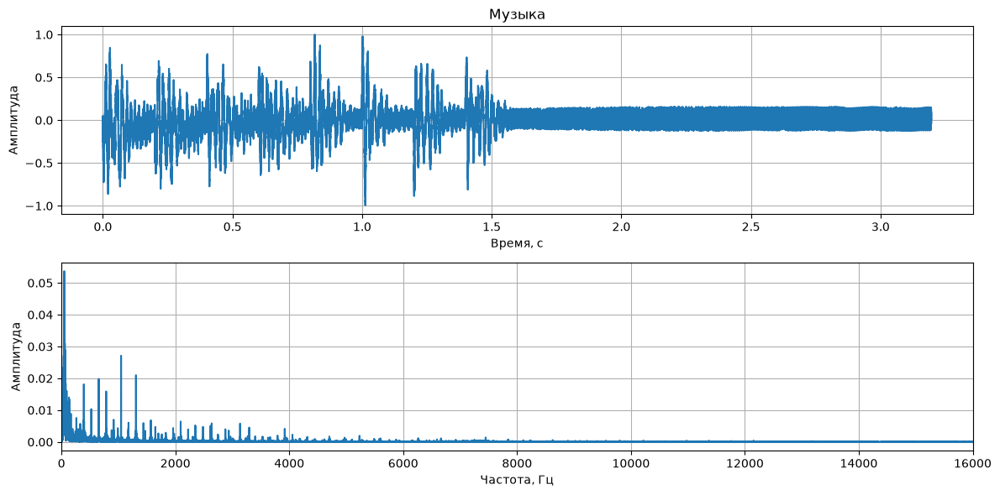

In [16]:
f_audio, amp_audio = amplitude_spectrum(melody, fs_audio)
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(t_audio, melody)
axes[0].set(xlabel='Время, с', ylabel='Амплитуда', title='Музыка')
axes[1].plot(f_audio, amp_audio)
axes[1].set(xlabel='Частота, Гц', ylabel='Амплитуда', xlim=(0, 16000))
plt.tight_layout()
plt.show()

**Вопрос:** До каких частот наблюдаются заметные пики в сигнале? Подумайте, какую частоту несущей можно выбрать при частоте дискретизации 44,1 кГц, чтобы эти пики не потерять. Как на это влияет выбор индекса модуляции ФМ-сигнала?

основные пики у меня в первых  килогерцах. несущая 10 кГц: при 44,1 кГц у нас верхняя граница 22,05 кГц Если сильно увеличить β, спектр расширится и часть полос не поместится.

### Задание 4.2. Подготовка к модуляции (интерполяция)

Выберите частоту несущей в соответствии с ответом на предыдущий вопрос (если восстановленный сигнал будет сильно зашумлён, попробуйте другие значения).

In [17]:
fc_high = 10000
Ac = 1
# В файле уже 44100 Гц, частоту дискретизации оставляю как есть.

### Модуляция аудиосигнала
Сгенерируйте модулированные сигналы. Индекс модуляции для ФМ-сигнала выберите так, чтобы несильно портить модулируемый сигнал.

In [18]:
a_am = 0.2
beta_pm_audio = 2
carrier_phase = 2*np.pi*fc_high*t_audio
s_am_audio = Ac*(1+a_am*melody)*np.cos(carrier_phase)
s_pm_audio = Ac*np.cos(carrier_phase + beta_pm_audio*melody)

### Добавление шумов

**Амплитудный шум:** мультипликативный гауссов шум.

In [19]:
noise_unit = rng.standard_normal(len(melody))
s_am_noisy = s_am_audio * (1 + 0.1*noise_unit)
s_pm_noisy = s_pm_audio * (1 + 0.1*noise_unit)

def demodulate_am(s, depth):
    return (abs(hilbert(s)) - 1) / depth

def demodulate_pm(s, beta):
    phase = np.unwrap(np.angle(hilbert(s))) - carrier_phase
    return (phase - phase.mean()) / beta

def audio_error(y):
    return np.std(y - melody)

### Задание 4.3. Демодуляция сигналов

**Демодуляция АМ:**

Используйте преобразование Гильберта, чтобы демодулировать АМ-сигнал без шума, убедитесь, что качество звука изменилось незначительно.

In [20]:
demod_am_audio = demodulate_am(s_am_audio, a_am)
print('Ошибка АМ без шума:', round(audio_error(demod_am_audio), 4))
display(Audio(demod_am_audio, rate=fs_audio))

Ошибка АМ без шума: 0.0149


Демодулируйте зашумлёный АМ-сигнал.

In [21]:
demod_am_noisy = demodulate_am(s_am_noisy, a_am)
display(Audio(demod_am_noisy, rate=fs_audio))
for sigma in [0.01, 0.03, 0.1, 0.2]:
    y = demodulate_am(s_am_audio*(1 + sigma*noise_unit), a_am)
    print('Шум:', sigma, 'ошибка:', round(audio_error(y), 4))
    display(Audio(y, rate=fs_audio))
print('Теперь меняю глубину АМ при шуме 0.01:')
for depth in [0.02, 0.05, 0.2, 0.5, 1]:
    s = (1 + depth*melody) * np.cos(carrier_phase)
    y = demodulate_am(s*(1 + 0.01*noise_unit), depth)
    print('Глубина:', depth, 'ошибка:', round(audio_error(y), 4))
    display(Audio(y, rate=fs_audio))

Шум:

 0.01 ошибка: 0.0452


Шум: 0.03 ошибка: 0.129


Шум: 0.1 ошибка: 0.4269


Шум: 0.2 ошибка: 0.8499


Теперь меняю глубину АМ при шуме 0.01:
Глубина: 0.02 ошибка: 0.448


Глубина: 0.05 ошибка: 0.1793


Глубина: 0.2 ошибка: 0.0452


Глубина: 0.5 ошибка: 0.0189


Глубина: 1 ошибка: 0.0108


**Вопросы:**
* Изменилось ли качество звука?
* Зафиксируйте $a_{AM}=0{,}2$. Попробуйте поменять амплитуду шума. При каких значениях амплитуды вы слышите заметную разницу с оригиналом?
* Зафиксируйте амплитуду шума равную 0,01. Попробуйте поменять $a_{AM}$, при каких амплитудах модуляции начинаются заметные искажения? Сделайте вывод о соотношении $a_{AM}$ и допустимых уровнях шума.

Без шума ошибка небольшая. При шуме 0,03 она растёт, а при 0,1 результат сильно плох. Плееры я оставил, чтобы можно было сравнить на слух.

При шуме 0,01 маленькая глубина 0,02–0,05 даёт ошибку: при восстановлении мы делим на глубину и усиливаем шум. Так что глубину лучше брать побольше.

**Демодуляция ФМ:**

Используйте метод аналитического сигнала для демодуляции ФМ-сигнала. Убедитесь, что качество звука изменилось незначительно.

In [22]:
demod_pm_audio = demodulate_pm(s_pm_audio, beta_pm_audio)
print('Ошибка ФМ без шума:', round(audio_error(demod_pm_audio), 4))
display(Audio(demod_pm_audio, rate=fs_audio))

Ошибка ФМ без шума: 0.0063


Демодулируйте зашумлёный ФМ-сигнал.

In [23]:
demod_pm_noisy = demodulate_pm(s_pm_noisy, beta_pm_audio)
display(Audio(demod_pm_noisy, rate=fs_audio))
for sigma in [0.01, 0.1, 0.2, 0.5]:
    y = demodulate_pm(s_pm_audio*(1 + sigma*noise_unit), 2)
    print('Шум:', sigma, 'ошибка:', round(audio_error(y), 4))
    display(Audio(y, rate=fs_audio))
print('Теперь меняю β при шуме 0.1:')
for beta in [0.1, 0.5, 1, 2, 5, 10]:
    s = np.cos(carrier_phase + beta*melody)
    y = demodulate_pm(s*(1 + 0.1*noise_unit), beta)
    print('β:', beta, 'ошибка:', round(audio_error(y), 4))
    display(Audio(y, rate=fs_audio))

Шум: 0.01 ошибка: 0.0069


Шум: 0.1 ошибка: 0.0272


Шум: 0.2 ошибка: 0.0549


Шум:

 0.5 ошибка: 469.4183


Теперь меняю β при шуме 0.1:
β: 0.1 ошибка: 0.5289


... (3 outputs left out)

β: 2 ошибка: 0.0272


β: 5 ошибка: 0.0122


β:

 10 ошибка: 0.2723


**Вопросы:**
* Изменилось ли качество звука?
* Зафиксируйте $\beta=2$. Попробуйте поменять амплитуду шума. При каких значениях амплитуды вы слышите заметную разницу с оригиналом?
* Зафиксируйте амплитуду шума равную 0,1. Попробуйте поменять $\beta$. Как субъективная величина искажений зависит от $\beta$?

ФМ в этом опыте лучше переносит амплитудный шум. Информация у нас в фазе, поэтому небольшие колебания громкости мешают меньше. Но при большом шуме появляются провалы амплитуды и результат резко ухудшатся.

С β тоже нужен баланс: маленькое значение усиливает фазовую ошибку при делении, а слишком большое расширяет спектр.

### Задание 4.4. Сравнение спектров

Выберите значение амплитуды шума и величин $a_{AM}$ и $\beta$ так, чтобы искажения были заметны, но не велики. Постройте спектры исходного сигнала и сигналов, восстановлённых из зашумлённых АМ и ФМ-сигналов.

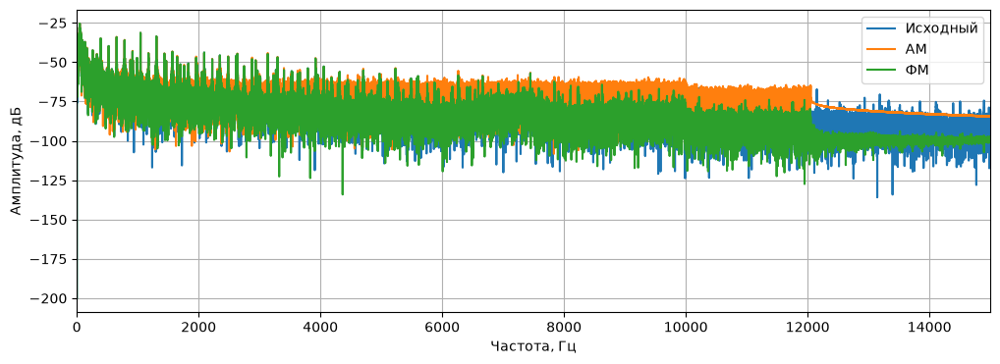

In [24]:
am_compare = demodulate_am(s_am_audio*(1 + 0.01*noise_unit), a_am)
pm_compare = demodulate_pm(s_pm_audio*(1 + 0.01*noise_unit), 2)
for y, label in [(melody, 'Исходный'), (am_compare, 'АМ'), (pm_compare, 'ФМ')]:
    f, amp = amplitude_spectrum(y, fs_audio)
    plt.plot(f, 20*np.log10(amp + 1e-10), label=label)
plt.xlim(0, 15000)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда, дБ')
plt.legend()
plt.show()

**Вопрос:**
* Заметны ли визуально искажения спектров для случаев АМ и ФМ?

 после АМ шумовой фон выше. У ФМ спектр ближе к начальнму, хотя полностью графики не совпадают. По одним высоким пикам это не видно.

Постройте спектры АМ и ФМ сигналов. Зафиксируйте $\beta=2$, подберите $a_{AM}$ так, чтобы амплитуды гармоник в обоих случаях были сравнимы по величине.

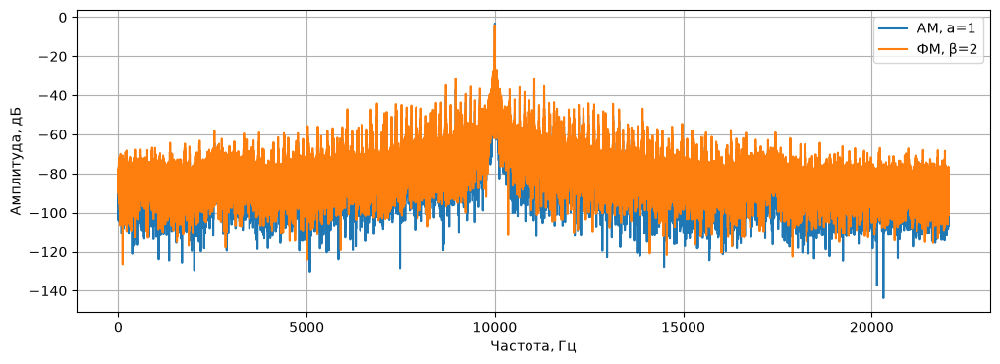

Шум: 0.01 ошибка АМ: 0.011 ошибка ФМ: 0.007


Шум: 0.1 ошибка АМ: 0.087 ошибка ФМ: 0.027


Шум: 0.3 ошибка АМ: 0.257 ошибка ФМ: 8.561


In [25]:
a_compare = 1
am = (1 + a_compare*melody) * np.cos(carrier_phase)
pm = np.cos(carrier_phase + 2*melody)
for y, label in [(am, 'АМ, a=1'), (pm, 'ФМ, β=2')]:
    f, amp = amplitude_spectrum(y, fs_audio)
    plt.plot(f, 20*np.log10(amp + 1e-10), label=label)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда, дБ')
plt.legend()
plt.show()
for sigma in [0.01, 0.1, 0.3]:
    gain = 1 + sigma*noise_unit
    y_am = demodulate_am(am*gain, a_compare)
    y_pm = demodulate_pm(pm*gain, 2)
    print('Шум:', sigma, 'ошибка АМ:', round(audio_error(y_am), 3),
          'ошибка ФМ:', round(audio_error(y_pm), 3))
    display(Audio(y_am, rate=fs_audio))
    display(Audio(y_pm, rate=fs_audio))

**Вопрос:**
* При какой амплитуде шума в этом случае вы слышите заметные искажения АМ сигнала? А ФМ сигнала? Сделайте вывод.

Я взял a=1 и β=2: боковые пики уже одного порядка, хотя точно не равны. При шуме 0,1 ФМ ещё выигрывает, а при 0,3 у фазового детектора могут бть большие ошибки. Получается, АМ ухудшается плавнее, а ФМ до некоторого уровня держится лучше, потом резко сдаёт. Точную границу слышимости тут лучше проверить на плеерах.

## Общий вывод

АМ мне показалась проще: взяли огибающую и получили сообщение. Но шум громкости сразу портит результат. ФМ такой шум переносит лучше, пока нормально определяется фаза. Ну и на настоящей музыке уже приходится внимательнее выбирать несущую и β: у неё спектр гораздо шире, чем у двух синусоид.